In [ ]:
import pandas as pd
df = pd.read_csv("Building_Permits_20260222-1-1.csv")
df.head(5)

/tmp/ipykernel_3439/2417743960.py:2: DtypeWarning: Columns (0,1,8,12,14,35,40,45,50,55,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104,107) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Building_Permits_20260222-1-1.csv")


,ID,PERMIT#,PERMIT_STATUS,PERMIT_MILESTONE,PERMIT_TYPE,REVIEW_TYPE,APPLICATION_START_DATE,ISSUE_DATE,PROCESSING_TIME,STREET_NUMBER,...,REPORTED_COST,PIN_LIST,COMMUNITY_AREA,CENSUS_TRACT,WARD,XCOORDINATE,YCOORDINATE,LATITUDE,LONGITUDE,LOCATION
0,3368573,101046020,NaN,NaN,PERMIT - SIGNS,SIGN PERMIT,3/8/2024,9/18/2024,194,7529.0,...,"$5,500.00",NaN,1.0,10202.0,49.0,1.162912e+06,1.950065e+06,42.018631,-87.675845,POINT (-87.675844598018 42.018631130261)
1,3423504,101072844,ACTIVE,INSPECTIONS,PERMIT - RENOVATION/ALTERATION,SELF CERT,8/8/2025,10/14/2025,67,2219.0,...,"$20,000.00",1730102015,31.0,841300.0,25.0,1.161422e+06,1.889146e+06,41.851494,-87.683028,POINT (-87.683027767753 41.851494345646)
2,2486241,100498645,NaN,NaN,PERMIT - EASY PERMIT PROCESS,EASY PERMIT,7/8/2013,7/8/2013,0,2648.0,...,"$24,815.00",1429408053,7.0,70400.0,32.0,1.168462e+06,1.917958e+06,41.930408,-87.656354,POINT (-87.656354338933 41.930408052126)
3,2487337,100499294,NaN,NaN,PERMIT - EASY PERMIT PROCESS,EASY PERMIT,7/11/2013,7/11/2013,0,9426.0,...,"$7,800.00",2503429023,49.0,490400.0,9.0,1.181524e+06,1.842462e+06,41.722950,-87.610690,POINT (-87.610689567581 41.722949542022)
4,2490603,100500984,NaN,NaN,PERMIT - EASY PERMIT PROCESS,EASY PERMIT,7/23/2013,7/23/2013,0,2236.0,...,"$9,950.00",1418102025,4.0,40600.0,47.0,1.160442e+06,1.931543e+06,41.967856,-87.685451,POINT (-87.685451345211 41.9678557176)


In [ ]:
# Remove '$', ',', and parentheses, then convert to numeric
df['REPORTED_COST'] = (
    df['REPORTED_COST']
    .replace(r'[$,()]', '', regex=True)
    .astype(float)
)

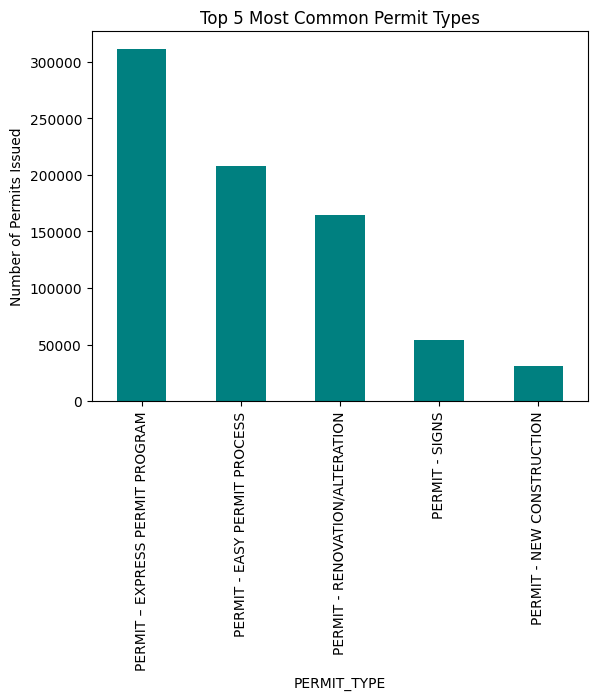

In [ ]:
#1
import matplotlib.pyplot as plt

top_types = df.groupby('PERMIT_TYPE').size().sort_values(ascending=False).head(5)
top_types.plot(kind='bar', color='teal')

plt.title("Top 5 Most Common Permit Types")
plt.ylabel("Number of Permits Issued")
plt.show()

The top 5 most common types of permit issued in Chicago are express permits, easy permits, renovation/alteration permits, sign permits, and new construction permits.

In [ ]:
#2
df['ISSUE_DATE'] = pd.to_datetime(df['ISSUE_DATE'])
df['ISSUE_DATE'].dt.year.value_counts().sort_index().loc[[2020, 2026]]

,count
ISSUE_DATE,
2020,38512
2026,3363


The number of permits issued in 2020 was significantly higher than 2026. However, the data for the year 2026 is only updated to February, which could explain the large difference in number of permits issued.

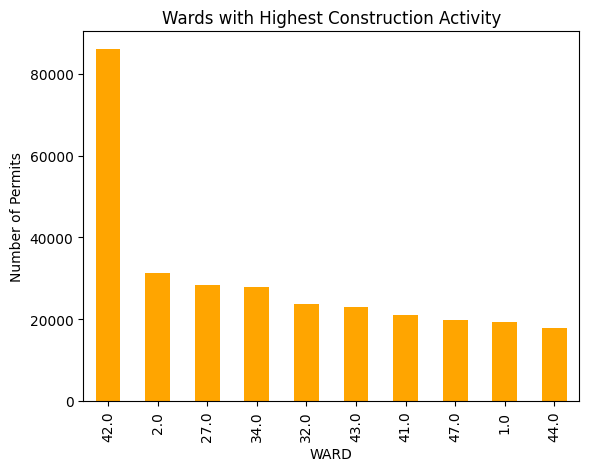

In [ ]:
#3
busiest_wards = df.groupby('WARD').size().sort_values(ascending=False).head(10)
busiest_wards.plot(kind='bar', color='orange')

plt.title("Wards with Highest Construction Activity")
plt.ylabel("Number of Permits")
plt.show()

Ward 42 in Chicago has the highest construction active with over 80,000 building permits being issued since 2006.

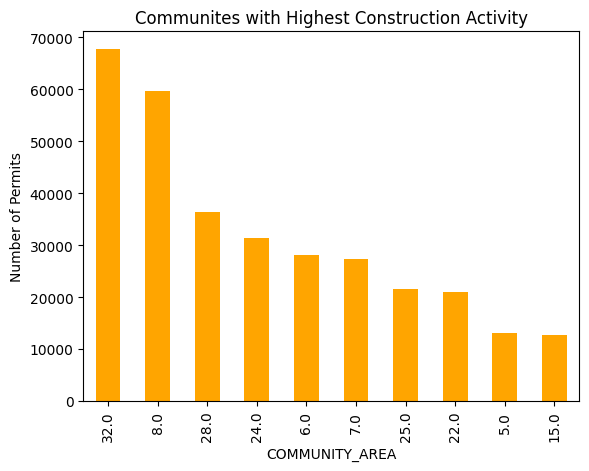

In [ ]:
#3
busiest_communites = df.groupby('COMMUNITY_AREA').size().sort_values(ascending=False).head(10)
busiest_communites.plot(kind='bar', color='orange')

plt.title("Communites with Highest Construction Activity")
plt.ylabel("Number of Permits")
plt.show()

Community 32, which is the
The Loop in Chicago, has the most contruction activity with just under 70,000 building permits being issued since 2006.


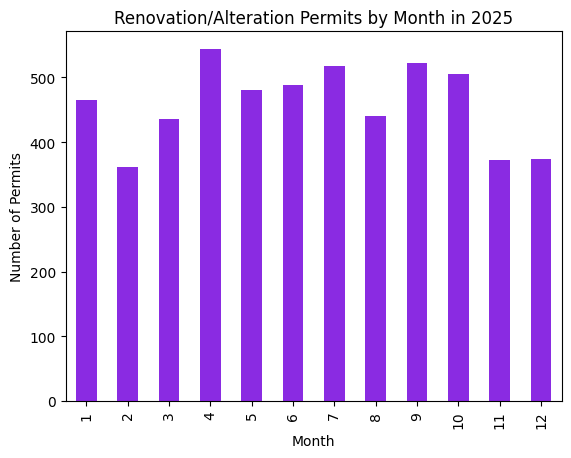

In [ ]:
#4
renovation_2025 = df[df['PERMIT_TYPE'] == 'PERMIT - RENOVATION/ALTERATION']
renovation_2025 = renovation_2025[renovation_2025['ISSUE_DATE'].dt.year == 2025]

renovation_2025.groupby(renovation_2025['ISSUE_DATE'].dt.month).size().plot(kind='bar', color='blueviolet')

plt.title('Renovation/Alteration Permits by Month in 2025')
plt.xlabel('Month')
plt.ylabel('Number of Permits')
plt.show()

The most renovation/alteration permits were issued in April of 2025 with over 500 permits being issued that month.

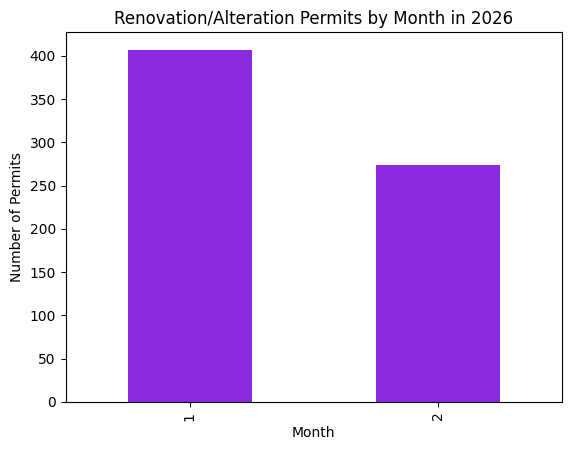

In [ ]:
#4
renovation_2026 = df[df['PERMIT_TYPE'] == 'PERMIT - RENOVATION/ALTERATION']
renovation_2026 = renovation_2026[renovation_2026['ISSUE_DATE'].dt.year == 2026]

renovation_2026.groupby(renovation_2026['ISSUE_DATE'].dt.month).size().plot(kind='bar', color='blueviolet')

plt.title('Renovation/Alteration Permits by Month in 2026')
plt.xlabel('Month')
plt.ylabel('Number of Permits')
plt.show()

So far, the data recorded in 2026 shows that the most renovation/alteration permits were issued in January with around 400 permits being issued.

In [ ]:
#5
busiest_communities = df.groupby('COMMUNITY_AREA').size().sort_values(ascending=False).head(5)

print(busiest_communities)

COMMUNITY_AREA
32.0    67747
8.0     59641
28.0    36353
24.0    31441
6.0     28055
dtype: int64


The 5 communities in Chicago with the most permits issued are Area 32 (The Loop), Area 8 (Near North Side), Area 28 (Near West Side), Area 24 (West Town), and Area 6 (Lake View).

In [ ]:
#6
permits_2025 = df[df['ISSUE_DATE'].dt.year == 2025]

approved = permits_2025['WORK_DESCRIPTION'].str.contains('approved', case=False, na=False).sum()

pending = permits_2025['WORK_DESCRIPTION'].str.contains('pending', case=False, na=False).sum()

under_review = permits_2025['WORK_DESCRIPTION'].str.contains('under review', case=False, na=False).sum()

print("Approved:", approved)
print("Pending:", pending)
print("Under review:", under_review)

Approved: 147
Pending: 42
Under review: 0


In 2025, there are 147 permits that have been approved, 42 that are pending, and 0 that are under review.

In [ ]:
#7
cost_by_review = df.groupby("REVIEW_TYPE")["REPORTED_COST"].agg(
    ["count", "median", "mean"]
)

cost_by_review = cost_by_review.sort_values(
    by="median", ascending=False
)

print(cost_by_review.head(10))

                                 count     median          mean
REVIEW_TYPE                                                    
DIRECT DEVELOPER SERVICES         2194  2000000.0  1.192878e+07
TRADITIONAL DEVELOPER SERVICES    5381   715000.0  7.613096e+06
SELF CERT                        52836   150000.0  4.754985e+05
STANDARD PLAN REVIEW            137873    30000.0  4.036888e+05
CONVEYANCE DEVICE PERMIT         21729    29554.0  1.900727e+05
EASY PERMIT WEB                  54370     7800.0  2.526445e+04
EASY PERMIT                     167508     4450.0  6.456619e+04
SIGN PERMIT                      53450     2000.0  5.620319e+03
EXPRESS PERMIT PROGRAM          276083     1500.0  6.275719e+04
DEMOLITION PERMIT                21618        1.0  1.359665e+04


Direct Developer Services had the highest median reported cost of ＄2,000,000, followed by Traditional Developer Services at ＄715,000. Self Cert had a median cost of ＄50,000, while Standard Plan Review had a median of ＄30,000. This suggests that developer services review types are associated with higher cost projects.

In [ ]:
#8
permit_analysis = df.groupby(
    ["COMMUNITY_AREA", "REVIEW_TYPE", "PERMIT_TYPE"]
).size().reset_index(name="Count")

permit_analysis = permit_analysis.sort_values(
    by="Count", ascending=False
)

print(permit_analysis.head(10))

      COMMUNITY_AREA             REVIEW_TYPE                      PERMIT_TYPE  \
513             32.0  EXPRESS PERMIT PROGRAM  PERMIT – EXPRESS PERMIT PROGRAM   
131              8.0  EXPRESS PERMIT PROGRAM  PERMIT – EXPRESS PERMIT PROGRAM   
447             28.0  EXPRESS PERMIT PROGRAM  PERMIT – EXPRESS PERMIT PROGRAM   
114              7.0  EXPRESS PERMIT PROGRAM  PERMIT – EXPRESS PERMIT PROGRAM   
515             32.0               SELF CERT   PERMIT - RENOVATION/ALTERATION   
382             24.0  EXPRESS PERMIT PROGRAM  PERMIT – EXPRESS PERMIT PROGRAM   
398             25.0  EXPRESS PERMIT PROGRAM  PERMIT – EXPRESS PERMIT PROGRAM   
126              8.0             EASY PERMIT     PERMIT - EASY PERMIT PROCESS   
98               6.0  EXPRESS PERMIT PROGRAM  PERMIT – EXPRESS PERMIT PROGRAM   
1182            76.0  EXPRESS PERMIT PROGRAM  PERMIT – EXPRESS PERMIT PROGRAM   

      Count  
513   38303  
131   25783  
447   15773  
114   10137  
515    9935  
382    9135  
398    859

This combination of data shows that Community area 32 (The Loop) using an express permit is the most common combination of area, review type, and permit type occuring nearly 40,000 times in the dataset.

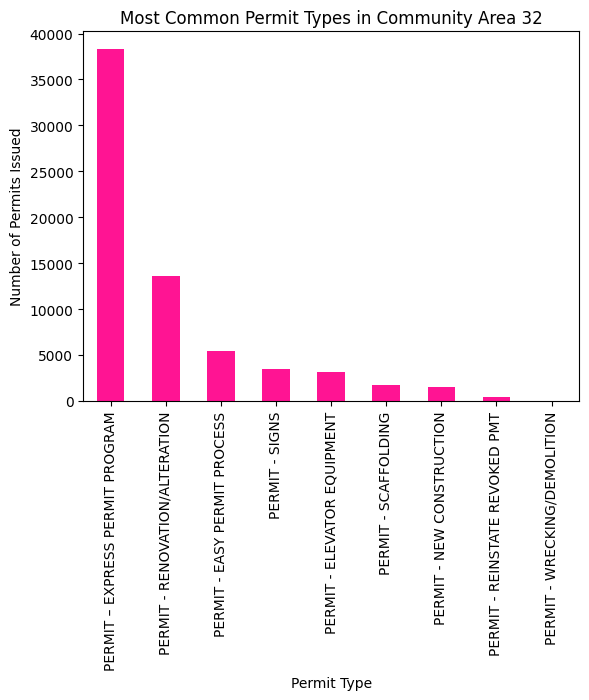

In [ ]:
#9
community_32 = df[df['COMMUNITY_AREA'] == 32]

top_types_32 = community_32.groupby('PERMIT_TYPE').size().sort_values(ascending=False)
top_types_32.plot(kind='bar', color='deeppink')

plt.title("Most Common Permit Types in Community Area 32")
plt.ylabel("Number of Permits Issued")
plt.xlabel("Permit Type")
plt.show()

The most common permit types issued in Community Area 32 (The Loop) are express permits, followed by renovation/alteration permits, and easy permits.

In [ ]:
#10
area_cost = df.groupby('COMMUNITY_AREA')['REPORTED_COST']
q1 = area_cost.transform('quantile', q=0.25)
q3 = area_cost.transform('quantile', q=0.75)
iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr
lower_bound = q1 - 1.5 * iqr
outliers = df[(df['REPORTED_COST'] > upper_bound) | (df['REPORTED_COST'] < lower_bound)]
print(outliers[['COMMUNITY_AREA', 'PERMIT_TYPE', 'REPORTED_COST']].sort_values('REPORTED_COST', ascending=False).head(10))

        COMMUNITY_AREA                      PERMIT_TYPE  REPORTED_COST
607118            35.0  PERMIT – EXPRESS PERMIT PROGRAM   1.000000e+10
146803            32.0   PERMIT - RENOVATION/ALTERATION   6.666667e+09
219038             8.0   PERMIT - RENOVATION/ALTERATION   6.666667e+09
157234            76.0   PERMIT - RENOVATION/ALTERATION   6.666667e+09
808412             8.0  PERMIT – EXPRESS PERMIT PROGRAM   1.934275e+09
283758             8.0   PERMIT - RENOVATION/ALTERATION   1.000000e+09
234740             8.0        PERMIT - NEW CONSTRUCTION   9.500000e+08
290207            48.0     PERMIT - EASY PERMIT PROCESS   8.725236e+08
298339            64.0     PERMIT - EASY PERMIT PROCESS   8.468189e+08
291647            73.0     PERMIT - EASY PERMIT PROCESS   8.094189e+08


Community area 35 (Douglas) had an extremely expensive express permit that cost ＄10 billion. Community area 8 (Near North Side) had 4 out of the 10 most expensive permits, ranging from ＄950 million to ＄6.6 billion.
